# Ejemplo de perceptrón en Python

**Materia:** Inteligencia Artificial
**Profesor:** José Mario Ríos Félix
**Alumno:** Jose de Jesus Quintero Noris
**No. de control:** 23170288

Se programa un perceptrón desde cero con NumPy y se usa para aprender las compuertas lógicas **AND** y **OR**. Después se prueba con **XOR**, que un solo perceptrón no puede aprender, para ver la limitación del modelo.

## 1. ¿Qué es un perceptrón?

Es el modelo más simple de neurona artificial y sirve para clasificar en dos clases (0 o 1). Funciona así:

1. Multiplica cada entrada por su **peso**.
2. Suma todo y le agrega un **sesgo** (*bias*): `z = w1·x1 + w2·x2 + b`.
3. Aplica una **función escalón**: si `z >= 0` responde 1, si no, responde 0.

**Regla de aprendizaje.** Se recorren los datos varias veces (épocas). Cada vez que el perceptrón se equivoca, corrige sus pesos:

```
error = clase_real - predicción
w = w + learning_rate * error * x
b = b + learning_rate * error
```

Si acierta, el error es 0 y no cambia nada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


class PerceptronSimple:
    """Perceptrón con función escalón, entrenado con la regla del perceptrón."""

    def __init__(self, learning_rate=0.1, epochs=20):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def escalon(self, z):
        return 1 if z >= 0 else 0

    def predecir_uno(self, x):
        z = np.dot(x, self.w) + self.b      # suma ponderada + sesgo
        return self.escalon(z)

    def predict(self, X):
        return np.array([self.predecir_uno(x) for x in X])

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])       # pesos iniciales en 0
        self.b = 0.0
        self.historial = []                 # (época, errores, w1, w2, b)

        for epoca in range(1, self.epochs + 1):
            errores = 0
            for x, real in zip(X, y):
                error = real - self.predecir_uno(x)
                if error != 0:
                    self.w = self.w + self.learning_rate * error * x
                    self.b = self.b + self.learning_rate * error
                    errores += 1
            self.historial.append((epoca, errores, self.w[0], self.w[1], self.b))
            if errores == 0:                # ya clasifica todo bien: termina
                break
        return self

## 2. Datos: compuertas lógicas

Cada compuerta recibe dos entradas (0 o 1) y devuelve 0 o 1. Son 4 combinaciones posibles.

| x1 | x2 | AND | OR | XOR |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 |

In [2]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

salidas = {
    'AND': np.array([0, 0, 0, 1]),
    'OR':  np.array([0, 1, 1, 1]),
    'XOR': np.array([0, 1, 1, 0]),
}
print("Entradas:\n", X)
for nombre, y in salidas.items():
    print(f"{nombre}: {y}")

Entradas:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
AND: [0 0 0 1]
OR: [0 1 1 1]
XOR: [0 1 1 0]


## 3. Entrenamiento con AND

Se muestra cómo cambian los pesos y el sesgo en cada época, para ver el aprendizaje paso a paso.

In [3]:
p_and = PerceptronSimple(learning_rate=0.1, epochs=20)
p_and.fit(X, salidas['AND'])

print("Época | Errores |    w1     w2       b")
print("-" * 40)
for epoca, errores, w1, w2, b in p_and.historial:
    print(f"{epoca:5d} | {errores:7d} | {w1:6.2f} {w2:6.2f} {b:7.2f}")

print()
print(f"Pesos finales: w1 = {p_and.w[0]:.2f}, w2 = {p_and.w[1]:.2f}, sesgo = {p_and.b:.2f}")

Época | Errores |    w1     w2       b
----------------------------------------
    1 |       2 |   0.10   0.10    0.00
    2 |       3 |   0.20   0.10   -0.10
    3 |       3 |   0.20   0.10   -0.20
    4 |       0 |   0.20   0.10   -0.20

Pesos finales: w1 = 0.20, w2 = 0.10, sesgo = -0.20


In [4]:
# Prueba: el perceptrón entrenado contra la tabla de verdad.
# Nota: para (1, 0) la suma da 0 (el "-0.00" es un error de redondeo mínimo del computador),
# o sea, ese punto cae justo sobre la frontera y queda del lado de la clase 0.
print("x1 x2 | z (suma) | salida | esperada")
for x, esperada in zip(X, salidas['AND']):
    z = np.dot(x, p_and.w) + p_and.b
    print(f" {x[0]}  {x[1]} | {z:8.2f} |   {p_and.predecir_uno(x)}    |    {esperada}")

x1 x2 | z (suma) | salida | esperada
 0  0 |    -0.20 |   0    |    0
 0  1 |    -0.10 |   0    |    0
 1  0 |    -0.00 |   0    |    0
 1  1 |     0.10 |   1    |    1


## 4. AND, OR y XOR

Se entrena un perceptrón nuevo para cada compuerta y se mide la exactitud (porcentaje de aciertos).

In [5]:
modelos = {}
for nombre, y in salidas.items():
    modelo = PerceptronSimple(learning_rate=0.1, epochs=20).fit(X, y)
    modelos[nombre] = modelo
    exactitud = np.mean(modelo.predict(X) == y)
    epocas_usadas = len(modelo.historial)
    print(f"{nombre:3s} -> exactitud: {exactitud:.0%} | épocas usadas: {epocas_usadas} "
          f"| w = {np.round(modelo.w, 2)}, b = {modelo.b:.2f}")

AND -> exactitud: 100% | épocas usadas: 4 | w = [0.2 0.1], b = -0.20
OR  -> exactitud: 100% | épocas usadas: 4 | w = [0.1 0.1], b = -0.10
XOR -> exactitud: 50% | épocas usadas: 20 | w = [-0.1  0. ], b = 0.00


## 5. Frontera de decisión

La recta `w1·x1 + w2·x2 + b = 0` separa lo que el perceptrón responde como 0 de lo que responde como 1. La zona naranja es la clase 1 y la azul la clase 0.

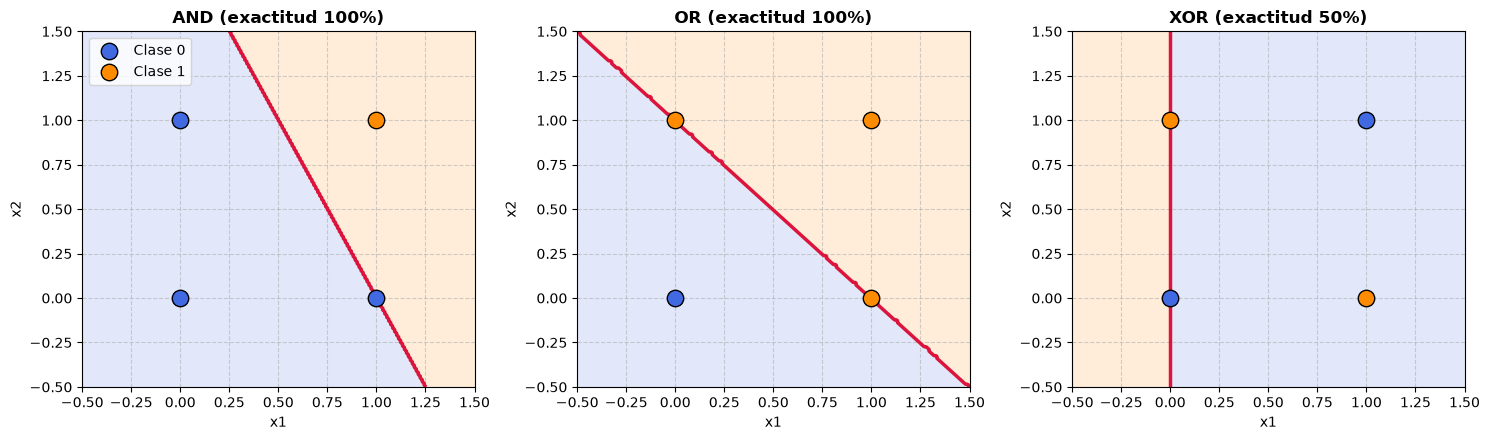

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# Rejilla de puntos para pintar las zonas
g1, g2 = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
rejilla = np.c_[g1.ravel(), g2.ravel()]

for eje, (nombre, modelo) in zip(ejes, modelos.items()):
    y = salidas[nombre]
    zonas = modelo.predict(rejilla).reshape(g1.shape)
    eje.contourf(g1, g2, zonas, levels=[-0.5, 0.5, 1.5], colors=['royalblue', 'darkorange'], alpha=0.15)
    eje.contour(g1, g2, zonas, levels=[0.5], colors='crimson', linewidths=2.5)

    eje.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='royalblue', s=140, label='Clase 0', zorder=5, edgecolor='black')
    eje.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='darkorange', s=140, label='Clase 1', zorder=5, edgecolor='black')

    exactitud = np.mean(modelo.predict(X) == y)
    eje.set_title(f'{nombre} (exactitud {exactitud:.0%})', fontweight='bold')
    eje.set_xlabel('x1')
    eje.set_ylabel('x2')
    eje.set_xlim(-0.5, 1.5)
    eje.set_ylim(-0.5, 1.5)
    eje.grid(True, linestyle='--', alpha=0.6)

ejes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

## 6. Evolución de los errores

Cuántos errores comete el perceptrón en cada época. Cuando llega a 0, ya aprendió. Si nunca llega a 0, el problema no se puede resolver con una sola recta.

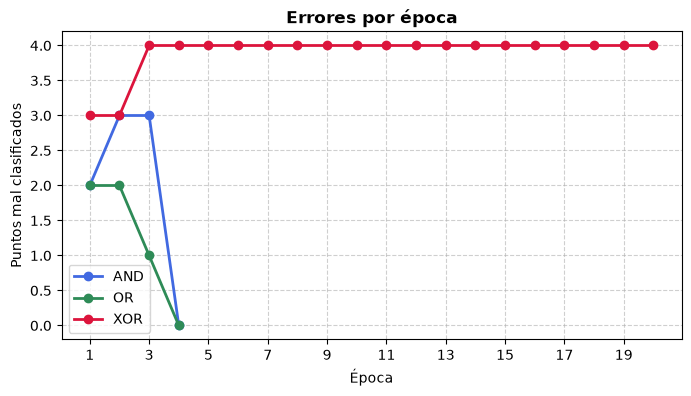

In [7]:
plt.figure(figsize=(8, 4))
colores = {'AND': 'royalblue', 'OR': 'seagreen', 'XOR': 'crimson'}
for nombre, modelo in modelos.items():
    errores = [h[1] for h in modelo.historial]
    plt.plot(range(1, len(errores) + 1), errores, marker='o', linewidth=2,
             color=colores[nombre], label=nombre)

plt.title('Errores por época', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Puntos mal clasificados')
plt.xticks(range(1, 21, 2))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Interpretación de los resultados

In [9]:
for nombre, modelo in modelos.items():
    y = salidas[nombre]
    exactitud = np.mean(modelo.predict(X) == y)
    if exactitud == 1.0:
        print(f"- {nombre}: aprendida al 100% en {len(modelo.historial)} épocas. "
              f"Recta: {modelo.w[0]:.2f}·x1 + {modelo.w[1]:.2f}·x2 + {modelo.b:.2f} = 0")
    else:
        print(f"- {nombre}: NO se pudo aprender. Con {len(modelo.historial)} épocas la exactitud "
              f"se quedó en {exactitud:.0%} y los errores nunca llegaron a 0.")

- AND: aprendida al 100% en 4 épocas. Recta: 0.20·x1 + 0.10·x2 + -0.20 = 0
- OR: aprendida al 100% en 4 épocas. Recta: 0.10·x1 + 0.10·x2 + -0.10 = 0
- XOR: NO se pudo aprender. Con 20 épocas la exactitud se quedó en 50% y los errores nunca llegaron a 0.


**Conclusiones**

- El perceptrón aprendió **AND** y **OR** porque en ambas compuertas los puntos de clase 0 y clase 1 se pueden separar con una sola línea recta (son *linealmente separables*).
- **XOR** no se pudo aprender: no existe ninguna recta que deje juntos los puntos (0,0) y (1,1) de un lado y (0,1) y (1,0) del otro. Los errores se quedan oscilando sin llegar a 0.
- Esta es la limitación clásica del perceptrón de una sola neurona. Para resolver XOR se necesita una red con **capa oculta** (varias neuronas) y funciones de activación no lineales, que es la idea de las redes neuronales multicapa.